# 01 - Minimal EDA: Default of Credit Card Clients (UCI id=350)

Covers target distribution, missing values and key variables. Run `python scripts/download_data.py` first (or `python -m credit_risk.train`, which downloads on demand).

In [1]:
import matplotlib.pyplot as plt

from credit_risk.data import CATEGORICAL_FEATURES, FEATURES, TARGET, load_dataset

df = load_dataset()
df.shape

(30000, 24)

## Target distribution
The classes are imbalanced, so accuracy is misleading; the project reports ROC-AUC, PR-AUC and Brier score.

default
no default    23364
default        6636
Name: count, dtype: int64
default rate: 22.120%


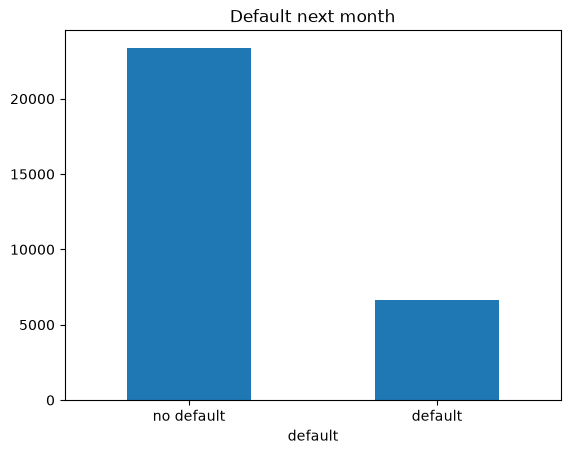

In [2]:
counts = df[TARGET].value_counts().rename({0: 'no default', 1: 'default'})
print(counts)
print(f'default rate: {df[TARGET].mean():.3%}')
counts.plot.bar(rot=0, title='Default next month')
plt.show()

## Missing values and types

In [3]:
print('missing cells:', int(df.isna().sum().sum()))
df.dtypes.value_counts()

missing cells: 0


int64    24
Name: count, dtype: int64

## Key variables
Demographic columns (SEX, EDUCATION, MARRIAGE, AGE) are sensitive; EDUCATION and MARRIAGE also contain undocumented codes (EDUCATION 0, 5, 6; MARRIAGE 0).

In [4]:
for col in CATEGORICAL_FEATURES:
    summary = df.groupby(col)[TARGET].agg(['size', 'mean']).rename(columns={'mean': 'default_rate'})
    print(f'\n{col}\n{summary.round(3)}')


SEX
      size  default_rate
SEX                     
1    11888         0.242
2    18112         0.208

EDUCATION
            size  default_rate
EDUCATION                     
0             14         0.000
1          10585         0.192
2          14030         0.237
3           4917         0.252
4            123         0.057
5            280         0.064
6             51         0.157

MARRIAGE
           size  default_rate
MARRIAGE                     
0            54         0.093
1         13659         0.235
2         15964         0.209
3           323         0.260


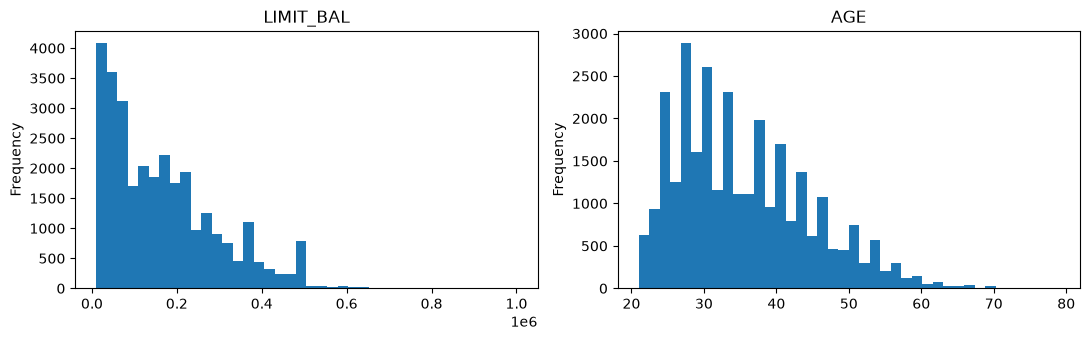

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df['LIMIT_BAL'].plot.hist(bins=40, ax=axes[0], title='LIMIT_BAL')
df['AGE'].plot.hist(bins=40, ax=axes[1], title='AGE')
plt.tight_layout()
plt.show()

`PAY_0` (repayment status in the most recent month) is the strongest signal: default rate rises sharply with months of delay.

In [6]:
df.groupby('PAY_0')[TARGET].agg(['size', 'mean']).rename(columns={'mean': 'default_rate'}).round(3)

,size,default_rate
PAY_0,,
-2,2759,0.132
-1,5686,0.168
0,14737,0.128
1,3688,0.339
2,2667,0.691
3,322,0.758
4,76,0.684
5,26,0.500
6,11,0.545


In [7]:
corr = df[[*FEATURES, TARGET]].corr()[TARGET].drop(TARGET)
corr.sort_values(key=abs, ascending=False).head(10).round(3)

PAY_0        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
LIMIT_BAL   -0.154
PAY_AMT1    -0.073
PAY_AMT2    -0.059
PAY_AMT4    -0.057
Name: default, dtype: float64